# Setup

In [1]:
# Cargar eda_wl_clean y configurar librerías
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

eda_wl_clean = pd.read_csv('../data/eda_wl_clean.csv')
# Convertir columnas de fecha a datetime por si hicieran falta
for col in ['date', 'w_dob', 'l_dob']:
    if col in eda_wl_clean.columns:
        eda_wl_clean[col] = pd.to_datetime(eda_wl_clean[col], errors='coerce')

print("eda_wl_clean cargado exitosamente.")

eda_wl_clean cargado exitosamente.


   MODELO BASELINE: ZeroR (Regla Cero)
ÚNICA REGLA: SIEMPRE predecir => Gana Rojo (1)

Accuracy en Prueba (Test): 0.5842

--- Reporte de Clasificación (Test) ---
               precision    recall  f1-score   support

Gana Azul (0)       0.00      0.00      0.00       506
Gana Rojo (1)       0.58      1.00      0.74       711

     accuracy                           0.58      1217
    macro avg       0.29      0.50      0.37      1217
 weighted avg       0.34      0.58      0.43      1217



# Preguntas



## Qué luchador tiene mayor probabilidad de ganar una pelea?

Respondo utilizando Random Forest para clasificación

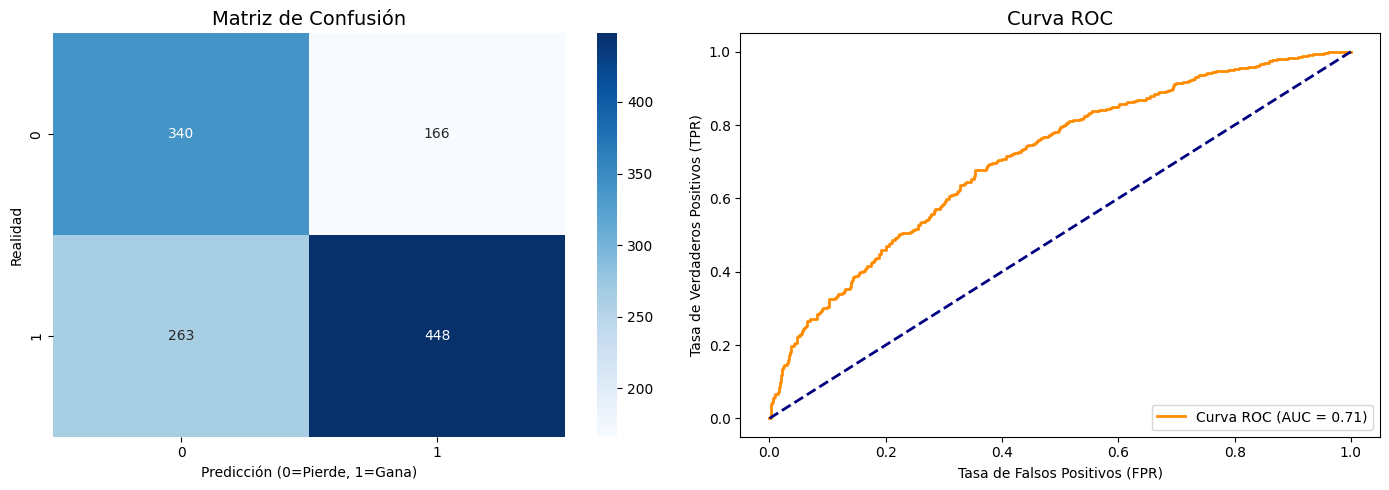

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import confusion_matrix, roc_curve, auc

# ==========================================
# 1. Preparación de variables y Manejo de NaNs (Dataset original - 1 fila por combate)
# ==========================================
df_podado = pd.read_csv('../data/df_podado.csv')
df_podado = df_podado.dropna(subset=['winner']).copy()
df_podado['is_winner'] = (df_podado['winner'] == df_podado['r_name']).astype(int)

features = ['height', 'reach', 'str_acc', 'td_acc', 'str_def', 'td_def', 'sapm', 'splm']
diff_features = []
for f in features:
    diff_name = f + '_diff'
    df_podado[diff_name] = pd.to_numeric(df_podado['r_' + f], errors='coerce') - pd.to_numeric(df_podado['b_' + f], errors='coerce')
    diff_features.append(diff_name)

X = df_podado[diff_features]
y = df_podado['is_winner']

# Imputación de NaNs en las variables predictoras usando la mediana (robusto a outliers)
imputer = SimpleImputer(strategy='median')
X_imputed = imputer.fit_transform(X)

# Separación en conjunto de entrenamiento y test
X_train, X_test, y_train, y_test = train_test_split(X_imputed, y, test_size=0.2, random_state=42)

# ==========================================
# 2. Entrenamiento del Modelo (Random Forest)
# ==========================================
rf_model = RandomForestClassifier(n_estimators=100, max_depth=5, random_state=42, class_weight='balanced')
rf_model.fit(X_train, y_train)

# ==========================================
# 3. Función predictiva de probabilidad
# ==========================================
def predict_win_probability(fighter_stats, model, imp):
    """
    Recibe un DataFrame de 1 fila con las métricas de un luchador,
    aplica la misma imputación del entrenamiento y devuelve la probabilidad de victoria.
    """
    stats_imputed = imp.transform(fighter_stats)
    # predict_proba devuelve [Prob_Clase0, Prob_Clase1]
    proba_victoria = model.predict_proba(stats_imputed)[0][1] 
    return proba_victoria

# Ejemplo de uso de la función (descomentar para probar):
# stats_luchador_ejemplo = pd.DataFrame([[180, 185, 45, 30, 55, 60, 3.5, 4.0]], columns=features)
# print("Probabilidad de ganar:", predict_win_probability(stats_luchador_ejemplo, rf_model, imputer))

# ==========================================
# 4. Evaluación del Modelo (Matriz y Curva ROC)
# ==========================================
y_pred = rf_model.predict(X_test)
y_proba = rf_model.predict_proba(X_test)[:, 1]

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Matriz de Confusión
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax[0])
ax[0].set_title('Matriz de Confusión', fontsize=14)
ax[0].set_xlabel('Predicción (0=Pierde, 1=Gana)')
ax[0].set_ylabel('Realidad')

# Curva ROC y AUC
fpr, tpr, thresholds = roc_curve(y_test, y_proba)
roc_auc = auc(fpr, tpr)
ax[1].plot(fpr, tpr, color='darkorange', lw=2, label=f'Curva ROC (AUC = {roc_auc:.2f})')
ax[1].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
ax[1].set_title('Curva ROC', fontsize=14)
ax[1].set_xlabel('Tasa de Falsos Positivos (FPR)')
ax[1].set_ylabel('Tasa de Verdaderos Positivos (TPR)')
ax[1].legend(loc="lower right")

plt.tight_layout()
plt.show()



## Evaluación extendida y Baseline
Se presenta el modelo base (baseline), un Árbol de Decisión, y las métricas detalladas por clase tanto en Train como en Test (matriz de confusión, precision, recall, f1).

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import time

# Baseline
baseline_rojo = 711
baseline_azul = 506
total_baseline = baseline_rojo + baseline_azul
baseline_acc = baseline_rojo / total_baseline
print(f"Baseline: {baseline_rojo} victorias del rojo, {baseline_azul} del azul => {baseline_acc:.2%} de predecir siempre rojo.")

# Entrenar Árbol de Decisión
dt_model = DecisionTreeClassifier(criterion='entropy', max_depth=5, random_state=42, class_weight='balanced')
start_time = time.time()
dt_model.fit(X_train, y_train)
dt_time = time.time() - start_time
print(f"Tiempo de entrenamiento (Árbol de Decisión): {dt_time:.4f} segundos")

y_train_pred = dt_model.predict(X_train)
y_test_pred = dt_model.predict(X_test)

tree_acc = accuracy_score(y_test, y_test_pred)
mejora_pp = (tree_acc - baseline_acc) * 100
print(f"Precisión del árbol en test: {tree_acc:.2%}")
print(f"Mejora con respecto al baseline: {mejora_pp:.2f} puntos porcentuales (pp).")

print("\n--- Métricas en Train ---")
print(classification_report(y_train, y_train_pred, target_names=['Gana Azul (0)', 'Gana Rojo (1)']))
print("\nMatriz de Confusión (Train):")
print(confusion_matrix(y_train, y_train_pred))

print("\n--- Métricas en Test ---")
print(classification_report(y_test, y_test_pred, target_names=['Gana Azul (0)', 'Gana Rojo (1)']))
print("\nMatriz de Confusión (Test):")
print(confusion_matrix(y_test, y_test_pred))


Baseline: 711 victorias del rojo, 506 del azul => 58.42% de predecir siempre rojo.
Tiempo de entrenamiento (Árbol de Decisión): 0.0291 segundos
Precisión del árbol en test: 60.89%
Mejora con respecto al baseline: 2.47 puntos porcentuales (pp).

--- Métricas en Train ---
               precision    recall  f1-score   support

Gana Azul (0)       0.54      0.78      0.64      2024
Gana Rojo (1)       0.77      0.53      0.63      2841

     accuracy                           0.64      4865
    macro avg       0.66      0.66      0.64      4865
 weighted avg       0.68      0.64      0.64      4865


Matriz de Confusión (Train):
[[1583  441]
 [1324 1517]]

--- Métricas en Test ---
               precision    recall  f1-score   support

Gana Azul (0)       0.52      0.74      0.61       506
Gana Rojo (1)       0.74      0.52      0.61       711

     accuracy                           0.61      1217
    macro avg       0.63      0.63      0.61      1217
 weighted avg       0.65      0.61  

# Modelo entrenado con las estadisticas reales

Este es el modelo con 65%

In [21]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt

# 1. Cargar el dataset (ERROR CORREGIDO: Faltaba esta línea)
df_podado = pd.read_csv('../data/df_podado.csv')

# Nos quedamos con las peleas que tienen un ganador claro usando los IDs, esto automáticamente elimina empates (Draws)
ml_df = df_podado.dropna(subset=['winner_id', 'r_id', 'b_id']).copy()

# 2. EL NUEVO MAPEO DEL TARGET (AÚN MEJOR Y MÁS SEGURO)
# Lógica: En lugar de comparar textos que pueden fallar, comparamos el ID del ganador (winner_id) con el ID del peleador rojo (r_id)
ml_df['target'] = np.where(ml_df['winner_id'] == ml_df['r_id'], 1, 0)

print("Balance del target (1=Gana Rojo, 0=Gana Azul):")
print(ml_df['target'].value_counts())
print()

# ERROR CORREGIDO: Calcular la edad a partir de la fecha de la pelea y la fecha de nacimiento.
# Primero convertimos las columnas a tipo "datetime"
ml_df['date'] = pd.to_datetime(ml_df['date'], errors='coerce')
ml_df['r_dob'] = pd.to_datetime(ml_df['r_dob'], errors='coerce')
ml_df['b_dob'] = pd.to_datetime(ml_df['b_dob'], errors='coerce')

# Calculamos la edad en años (dividimos los días entre 365.25 para tener en cuenta los bisiestos)
ml_df['r_age'] = (ml_df['date'] - ml_df['r_dob']).dt.days / 365.25
ml_df['b_age'] = (ml_df['date'] - ml_df['b_dob']).dt.days / 365.25

# Seleccionamos variables estrictamente PREVIAS a la pelea
features_red = ['r_age', 'r_height', 'r_reach', 'r_weight', 'r_wins', 'r_losses',
                'r_str_acc', 'r_sapm', 'r_str_def', 'r_td_avg', 'r_td_def', 'r_sub_avg']
features_blue = ['b_age', 'b_height', 'b_reach', 'b_weight', 'b_wins', 'b_losses',
                    'b_str_acc', 'b_sapm', 'b_str_def', 'b_td_avg', 'b_td_def', 'b_sub_avg']

# Para simplificar y mejorar la convergencia, usamos las DIFERENCIAS entre rincón rojo y azul
# Al modelo le importa más quién es más alto, más preciso o mejor defensor relativo a su oponente
ml_df['diff_age'] = ml_df['r_age'] - ml_df['b_age']
ml_df['diff_height'] = ml_df['r_height'] - ml_df['b_height']
ml_df['diff_reach'] = ml_df['r_reach'] - ml_df['b_reach']
ml_df['diff_weight'] = ml_df['r_weight'] - ml_df['b_weight']
ml_df['diff_wins'] = ml_df['r_wins'] - ml_df['b_wins']
ml_df['diff_losses'] = ml_df['r_losses'] - ml_df['b_losses']

# Nuevas variables técnicas (estadísticas de carrera pre-pelea)
# Esto permite responder "¿Qué tipo de pelea me conviene aceptar?" basado en ventajas de estilo.
ml_df['diff_str_acc'] = ml_df['r_str_acc'] - ml_df['b_str_acc']
ml_df['diff_sapm'] = ml_df['r_sapm'] - ml_df['b_sapm']
ml_df['diff_str_def'] = ml_df['r_str_def'] - ml_df['b_str_def']
ml_df['diff_td_avg'] = ml_df['r_td_avg'] - ml_df['b_td_avg']
ml_df['diff_td_def'] = ml_df['r_td_def'] - ml_df['b_td_def']
ml_df['diff_sub_avg'] = ml_df['r_sub_avg'] - ml_df['b_sub_avg']

features_diff = [
    'diff_age', 'diff_height', 'diff_reach', 'diff_weight', 'diff_wins', 'diff_losses',
    'diff_str_acc', 'diff_sapm', 'diff_str_def', 'diff_td_avg', 'diff_td_def', 'diff_sub_avg'
]

# Imputar valores nulos con la mediana para no perder filas importantes
for col in features_diff:
    ml_df[col] = ml_df[col].fillna(ml_df[col].median())

X = ml_df[features_diff]
y = ml_df['target']

# División en datos de entrenamiento (80%) y prueba (20%) con 'stratify' para mantener proporciones
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f"Set de entrenamiento: {X_train.shape[0]} peleas")
print(f"Set de prueba: {X_test.shape[0]} peleas")

Balance del target (1=Gana Rojo, 0=Gana Azul):
target
1    3552
0    2530
Name: count, dtype: int64

Set de entrenamiento: 4865 peleas
Set de prueba: 1217 peleas


## Naive Bayes

In [18]:
# ----------------------------------------------------
# Modelo 1: Naïve Bayes Gaussiano
# ----------------------------------------------------
# Asume que las características numéricas siguen una distribución normal
nb_model = GaussianNB()
nb_model.fit(X_train, y_train)

# Predicción y Evaluación
y_pred_nb = nb_model.predict(X_test)
acc_nb = accuracy_score(y_test, y_pred_nb)

print("--- Naïve Bayes Gaussiano ---")
print(f"Accuracy: {acc_nb:.4f}\n")
print("Reporte de Clasificación:")
print(classification_report(y_test, y_pred_nb, labels=[0, 1], target_names=['Gana Blue (0)', 'Gana Red (1)'], zero_division=0))

--- Naïve Bayes Gaussiano ---
Accuracy: 0.6500

Reporte de Clasificación:
               precision    recall  f1-score   support

Gana Blue (0)       0.59      0.53      0.56       506
 Gana Red (1)       0.69      0.74      0.71       711

     accuracy                           0.65      1217
    macro avg       0.64      0.63      0.63      1217
 weighted avg       0.65      0.65      0.65      1217



## Arbol de Clasificación

--- Árbol de Decisión (Entropía) ---
Accuracy: 0.6574

Reporte de Clasificación:
               precision    recall  f1-score   support

Gana Blue (0)       0.64      0.41      0.50       506
 Gana Red (1)       0.66      0.84      0.74       711

     accuracy                           0.66      1217
    macro avg       0.65      0.62      0.62      1217
 weighted avg       0.65      0.66      0.64      1217



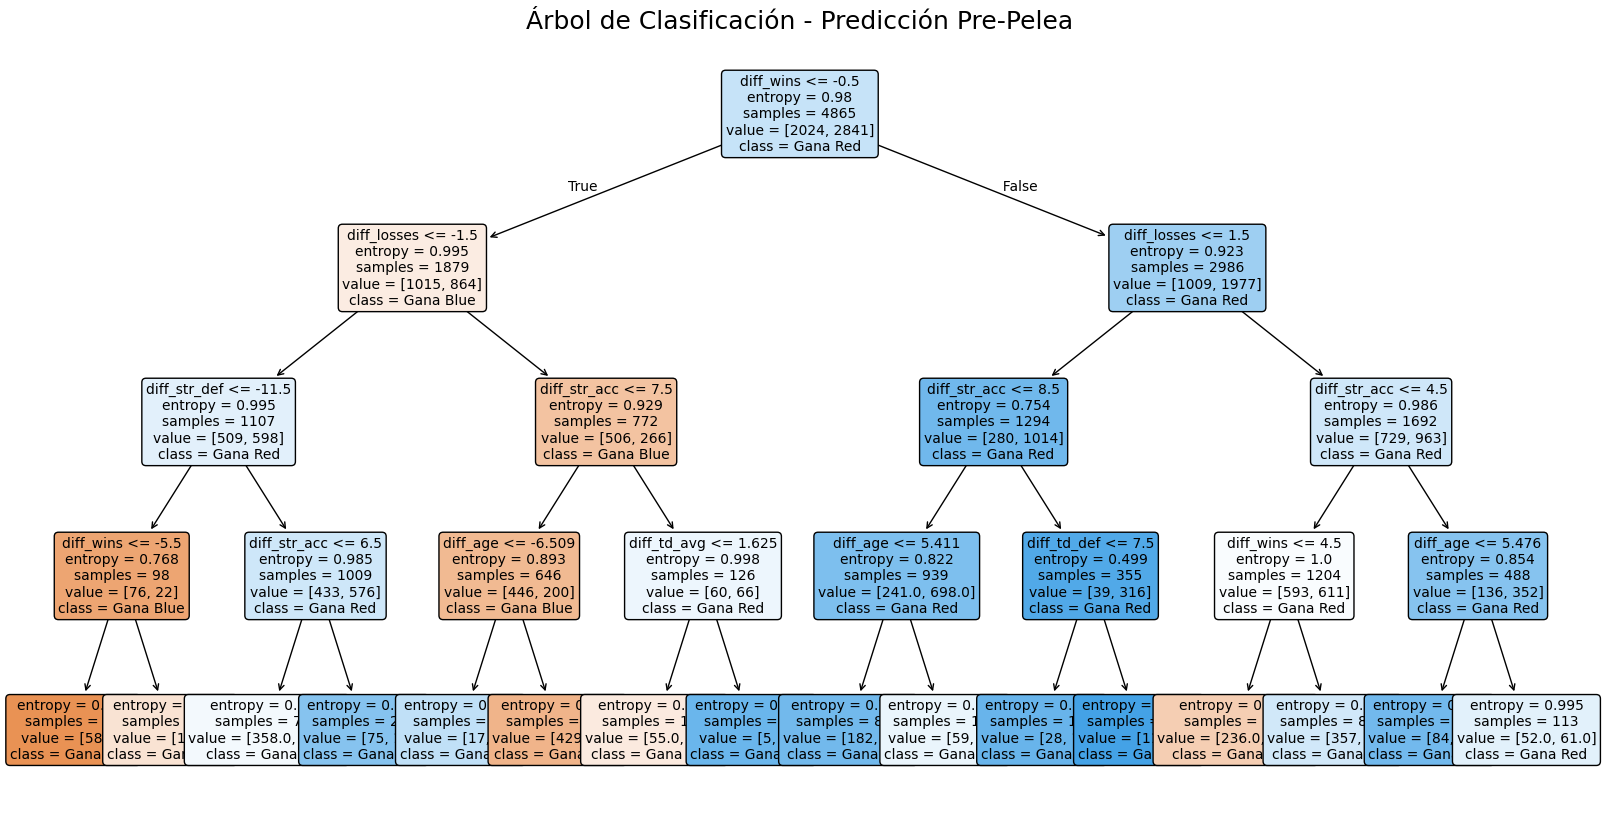

In [19]:
# ----------------------------------------------------
# Modelo 2: Árbol de Clasificación (C4.5 equivalent - CART)
# ----------------------------------------------------
# criterion="entropy" simula el enfoque de ganancia de información usado en algoritmos como ID3/C4.5
# controlamos max_depth para prevenir sobreajuste (overfitting) común en los árboles de decisión
dt_model = DecisionTreeClassifier(criterion='entropy', max_depth=4, random_state=42)
dt_model.fit(X_train, y_train)

# Predicción y Evaluación
y_pred_dt = dt_model.predict(X_test)
acc_dt = accuracy_score(y_test, y_pred_dt)

print("--- Árbol de Decisión (Entropía) ---")
print(f"Accuracy: {acc_dt:.4f}\n")
print("Reporte de Clasificación:")
print(classification_report(y_test, y_pred_dt, labels=[0, 1], target_names=['Gana Blue (0)', 'Gana Red (1)'], zero_division=0))

# Gráfico del Árbol de Decisión
plt.figure(figsize=(20, 10))
plot_tree(dt_model, 
          feature_names=features_diff, 
          class_names=['Gana Blue', 'Gana Red'], 
          filled=True, 
          rounded=True,
          fontsize=10)
plt.title("Árbol de Clasificación - Predicción Pre-Pelea", fontsize=18)
plt.show()

## Métricas de NB: Matriz de confusión y F1 

In [20]:
from sklearn.metrics import confusion_matrix, classification_report

# 1. Realizar las predicciones tanto en entrenamiento como en prueba
y_pred_train = nb_model.predict(X_train)
y_pred_test = nb_model.predict(X_test)

# 2. Imprimir los resultados para el set de ENTRENAMIENTO (Train)
print("==================================================")
print("   RESULTADOS EN ENTRENAMIENTO (TRAIN)")
print("==================================================")
print("\n--- Matriz de Confusión (Train) ---")
print(confusion_matrix(y_train, y_pred_train))
print("\n--- Reporte de Clasificación (Train) ---")
print(classification_report(y_train, y_pred_train, target_names=['Gana Azul (0)', 'Gana Rojo (1)']))

# 3. Imprimir los resultados para el set de PRUEBA (Test)
print("\n" + "="*50)
print("   RESULTADOS EN PRUEBA (TEST)")
print("==================================================")
print("\n--- Matriz de Confusión (Test) ---")
print(confusion_matrix(y_test, y_pred_test))
print("\n--- Reporte de Clasificación (Test) ---")
print(classification_report(y_test, y_pred_test, target_names=['Gana Azul (0)', 'Gana Rojo (1)']))

   RESULTADOS EN ENTRENAMIENTO (TRAIN)

--- Matriz de Confusión (Train) ---
[[1173  851]
 [ 725 2116]]

--- Reporte de Clasificación (Train) ---
               precision    recall  f1-score   support

Gana Azul (0)       0.62      0.58      0.60      2024
Gana Rojo (1)       0.71      0.74      0.73      2841

     accuracy                           0.68      4865
    macro avg       0.67      0.66      0.66      4865
 weighted avg       0.67      0.68      0.67      4865


   RESULTADOS EN PRUEBA (TEST)

--- Matriz de Confusión (Test) ---
[[268 238]
 [188 523]]

--- Reporte de Clasificación (Test) ---
               precision    recall  f1-score   support

Gana Azul (0)       0.59      0.53      0.56       506
Gana Rojo (1)       0.69      0.74      0.71       711

     accuracy                           0.65      1217
    macro avg       0.64      0.63      0.63      1217
 weighted avg       0.65      0.65      0.65      1217



## Metricas del Arbol

In [22]:
from sklearn.metrics import confusion_matrix, classification_report

# 1. Realizar las predicciones con el ÁRBOL DE DECISIÓN
y_pred_train_dt = dt_model.predict(X_train)
y_pred_test_dt = dt_model.predict(X_test)

# 2. Imprimir los resultados para el set de ENTRENAMIENTO (Train)
print("==================================================")
print("   ÁRBOL DE DECISIÓN: RESULTADOS EN ENTRENAMIENTO")
print("==================================================")
print("\n--- Matriz de Confusión (Train) ---")
print(confusion_matrix(y_train, y_pred_train_dt))
print("\n--- Reporte de Clasificación (Train) ---")
print(classification_report(y_train, y_pred_train_dt, target_names=['Gana Azul (0)', 'Gana Rojo (1)']))

# 3. Imprimir los resultados para el set de PRUEBA (Test)
print("\n" + "="*50)
print("   ÁRBOL DE DECISIÓN: RESULTADOS EN PRUEBA (TEST)")
print("==================================================")
print("\n--- Matriz de Confusión (Test) ---")
print(confusion_matrix(y_test, y_pred_test_dt))
print("\n--- Reporte de Clasificación (Test) ---")
print(classification_report(y_test, y_pred_test_dt, target_names=['Gana Azul (0)', 'Gana Rojo (1)']))

   ÁRBOL DE DECISIÓN: RESULTADOS EN ENTRENAMIENTO

--- Matriz de Confusión (Train) ---
[[ 796 1228]
 [ 388 2453]]

--- Reporte de Clasificación (Train) ---
               precision    recall  f1-score   support

Gana Azul (0)       0.67      0.39      0.50      2024
Gana Rojo (1)       0.67      0.86      0.75      2841

     accuracy                           0.67      4865
    macro avg       0.67      0.63      0.62      4865
 weighted avg       0.67      0.67      0.65      4865


   ÁRBOL DE DECISIÓN: RESULTADOS EN PRUEBA (TEST)

--- Matriz de Confusión (Test) ---
[[206 300]
 [117 594]]

--- Reporte de Clasificación (Test) ---
               precision    recall  f1-score   support

Gana Azul (0)       0.64      0.41      0.50       506
Gana Rojo (1)       0.66      0.84      0.74       711

     accuracy                           0.66      1217
    macro avg       0.65      0.62      0.62      1217
 weighted avg       0.65      0.66      0.64      1217



# ZeroR y reglas interesantes

Ejecuto ZeroR y obtengo las tres reglas más interesantes que nos provee.

In [24]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, classification_report

# 1. Instanciar y entrenar ZeroR (Predice siempre la clase mayoritaria)
# Usamos las mismas variables X_train, y_train que ya definiste en tu notebook
zero_r = DummyClassifier(strategy='most_frequent')
zero_r.fit(X_train, y_train)

# 2. Predecir
y_pred_zr = zero_r.predict(X_test)

# 3. Mostrar resultados
print("==================================================")
print("   MODELO BASELINE: ZeroR (Regla Cero)")
print("==================================================")
clase_mayoritaria = "Gana Rojo (1)" if zero_r.classes_[zero_r.class_prior_.argmax()] == 1 else "Gana Azul (0)"
print(f"ÚNICA REGLA: SIEMPRE predecir => {clase_mayoritaria}\n")

print(f"Accuracy en Prueba (Test): {accuracy_score(y_test, y_pred_zr):.4f}")
print("\n--- Reporte de Clasificación (Test) ---")
print(classification_report(y_test, y_pred_zr, target_names=['Gana Azul (0)', 'Gana Rojo (1)'], zero_division=0))

   MODELO BASELINE: ZeroR (Regla Cero)
ÚNICA REGLA: SIEMPRE predecir => Gana Rojo (1)

Accuracy en Prueba (Test): 0.5842

--- Reporte de Clasificación (Test) ---
               precision    recall  f1-score   support

Gana Azul (0)       0.00      0.00      0.00       506
Gana Rojo (1)       0.58      1.00      0.74       711

     accuracy                           0.58      1217
    macro avg       0.29      0.50      0.37      1217
 weighted avg       0.34      0.58      0.43      1217



# Reglas de Asociación

Utilizamos RAs para complementar el análisis

In [26]:
import pandas as pd
from mlxtend.frequent_patterns import apriori, association_rules

print("==================================================")
print("   MODELO 4: REGLAS DE ASOCIACIÓN (Apriori)")
print("==================================================")

# 1. Discretizar los datos (Transformar diferencias numéricas en atributos booleanos)
df_ra = pd.DataFrame()

# Si la diferencia es > 0, significa que el peleador Rojo tiene ventaja en ese atributo
df_ra['Ventaja_Alcance'] = ml_df['diff_reach'] > 0
df_ra['Ventaja_Golpeo'] = ml_df['diff_str_acc'] > 0
df_ra['Ventaja_Defensa'] = ml_df['diff_str_def'] > 0
df_ra['Ventaja_Derribos'] = ml_df['diff_td_avg'] > 0
df_ra['Racha_Victorias'] = ml_df['diff_wins'] > 0

# Nuestro atributo objetivo: Que el peleador Rojo gane
df_ra['Victoria'] = ml_df['target'] == 1

# 2. Aplicar Apriori para encontrar Itemsets Frecuentes (Soporte mínimo del 10%)
frequent_itemsets = apriori(df_ra, min_support=0.10, use_colnames=True)

# 3. Generar las Reglas de Asociación
reglas = association_rules(frequent_itemsets, metric="confidence", min_threshold=0.55)

# 4. Filtrar: Solo nos importan las reglas donde el consecuente sea ganar la pelea
reglas_victoria = reglas[reglas['consequents'] == frozenset({'Victoria'})]

# Ordenar por 'Lift' (Interés) y 'Confidence'
reglas_victoria = reglas_victoria.sort_values(by=['lift', 'confidence'], ascending=[False, False])

print(f"Total de reglas interesantes encontradas: {len(reglas_victoria)}\n")
print("--- LAS 3 REGLAS MÁS INTERESANTES (Mayor Interés/Lift) ---")

# Imprimir las top 3 de forma prolija
for i, row in reglas_victoria.head(5).iterrows():
    antecedentes = " Y ".join(list(row['antecedents']))
    print(f"REGLA {i+1}:")
    print(f"SI [{antecedentes}] => ENTONCES [Gana la Pelea]")
    print(f"  - Soporte:   {row['support']:.4f} (La regla cubre el {row['support']*100:.1f}% de las peleas)")
    print(f"  - Confianza: {row['confidence']:.4f} (Probabilidad de victoria si se cumple la regla)")
    print(f"  - Lift:      {row['lift']:.4f} (Interés: > 1 indica relación positiva fuerte)\n")

   MODELO 4: REGLAS DE ASOCIACIÓN (Apriori)
Total de reglas interesantes encontradas: 19

--- LAS 3 REGLAS MÁS INTERESANTES (Mayor Interés/Lift) ---
REGLA 65:
SI [Ventaja_Golpeo Y Racha_Victorias Y Ventaja_Derribos] => ENTONCES [Gana la Pelea]
  - Soporte:   0.1259 (La regla cubre el 12.6% de las peleas)
  - Confianza: 0.7698 (Probabilidad de victoria si se cumple la regla)
  - Lift:      1.3182 (Interés: > 1 indica relación positiva fuerte)

REGLA 61:
SI [Ventaja_Golpeo Y Ventaja_Defensa Y Racha_Victorias] => ENTONCES [Gana la Pelea]
  - Soporte:   0.1273 (La regla cubre el 12.7% de las peleas)
  - Confianza: 0.7656 (Probabilidad de victoria si se cumple la regla)
  - Lift:      1.3109 (Interés: > 1 indica relación positiva fuerte)

REGLA 42:
SI [Ventaja_Golpeo Y Racha_Victorias] => ENTONCES [Gana la Pelea]
  - Soporte:   0.2156 (La regla cubre el 21.6% de las peleas)
  - Confianza: 0.7453 (Probabilidad de victoria si se cumple la regla)
  - Lift:      1.2762 (Interés: > 1 indica rela